In [1]:
#Random Forest
#Glass Classification using Random Forest, Bagging, and Boosting
#1. Exploratory Data Analysis (EDA)
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_excel('glass.xlsx', sheet_name='glass')
print("Dataset Shape:", df.shape)
print("\nFirst 3 rows:\n", df.head(3))

# Check for missing values
print("\nMissing Values per column:\n", df.isnull().sum())

# Inspect Target Class Distribution ('Type')
print("\nClass Distribution:\n", df['Type'].value_counts())

Dataset Shape: (214, 10)

First 3 rows:
         RI     Na    Mg    Al     Si     K    Ca   Ba   Fe  Type
0  1.52101  13.64  4.49  1.10  71.78  0.06  8.75  0.0  0.0     1
1  1.51761  13.89  3.60  1.36  72.73  0.48  7.83  0.0  0.0     1
2  1.51618  13.53  3.55  1.54  72.99  0.39  7.78  0.0  0.0     1

Missing Values per column:
 RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

Class Distribution:
 Type
2    76
1    70
7    29
3    17
5    13
6     9
Name: count, dtype: int64


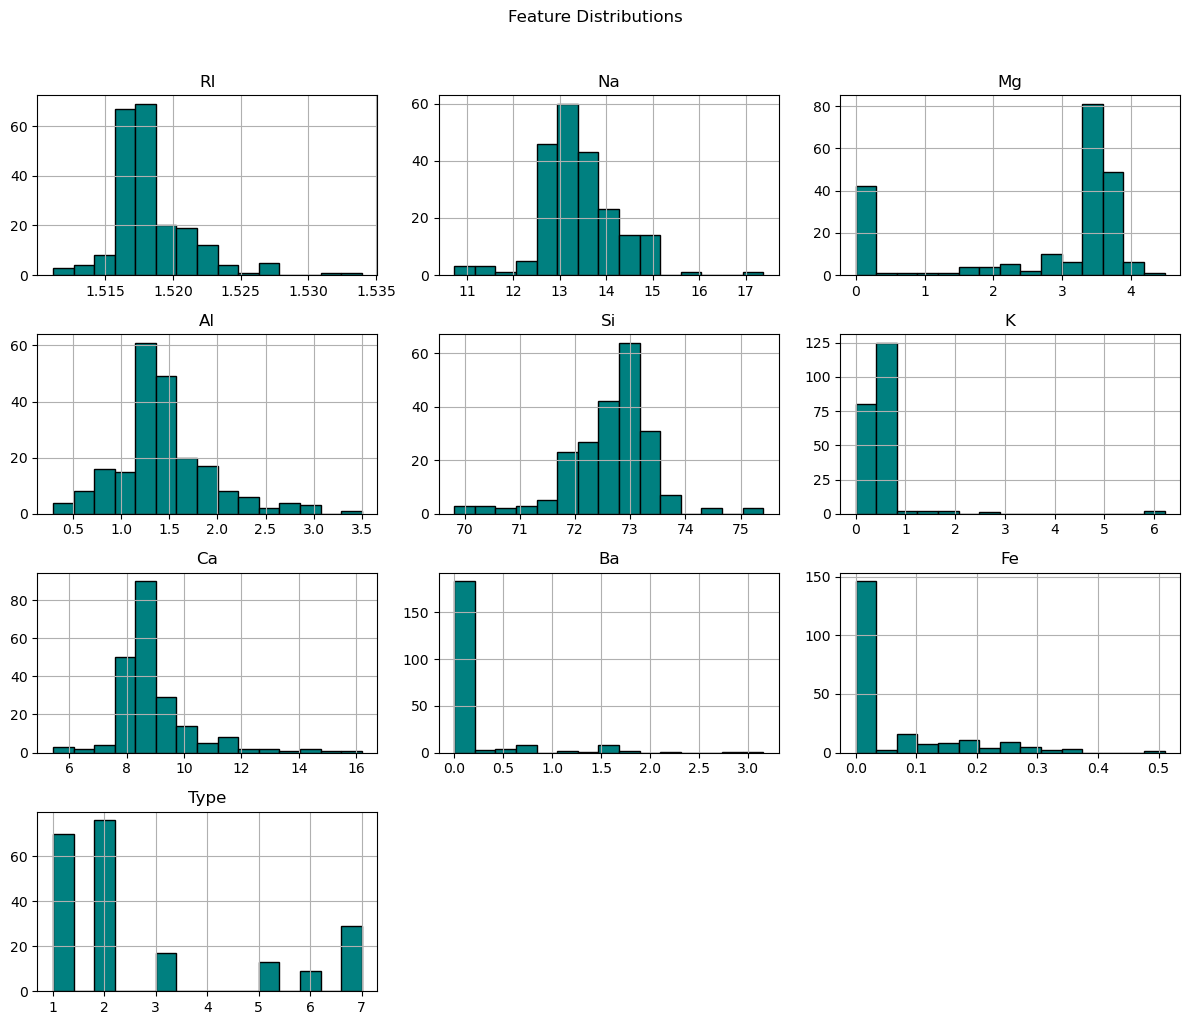

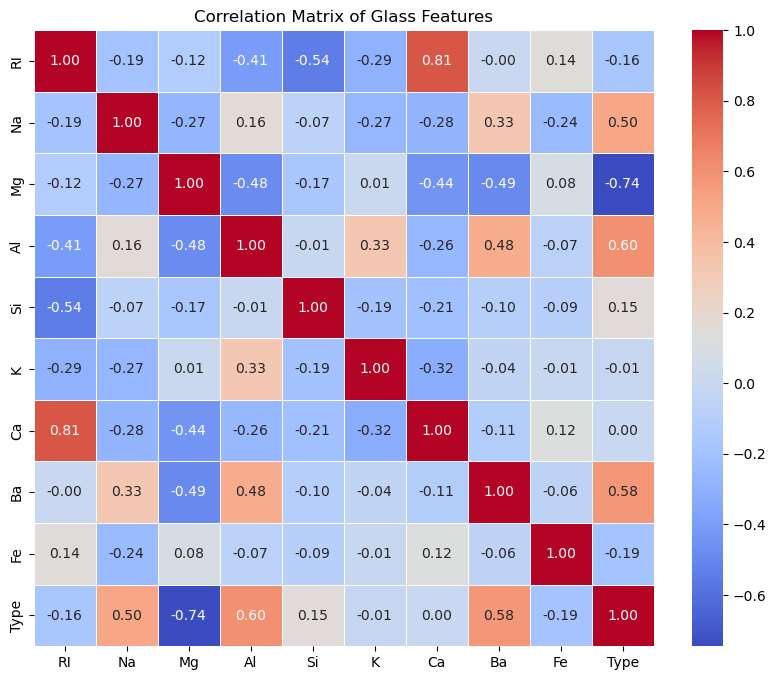

In [2]:
#2. Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Histograms for numerical features
df.hist(bins=15, figsize=(12, 10), color='teal', edgecolor='black')
plt.suptitle('Feature Distributions', y=1.02)
plt.tight_layout()
plt.show()

# Correlation Matrix Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Glass Features')
plt.show()

In [3]:
#3. Data Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df.drop(columns=['Type'])
y = df['Type']

# Stratified Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling (Standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [4]:
#4. Random Forest Model Implementation
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Initialize and train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test_scaled)

# Evaluation Metrics
print(f"Random Forest Accuracy:  {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Random Forest Precision: {precision_score(y_test, y_pred_rf, average='weighted', zero_division=0):.4f}")
print(f"Random Forest Recall:    {recall_score(y_test, y_pred_rf, average='weighted', zero_division=0):.4f}")
print(f"Random Forest F1-Score:  {f1_score(y_test, y_pred_rf, average='weighted', zero_division=0):.4f}")

print("\nClassification Report:\n", classification_report(y_test, y_pred_rf, zero_division=0))

Random Forest Accuracy:  0.8372
Random Forest Precision: 0.8542
Random Forest Recall:    0.8372
Random Forest F1-Score:  0.8355

Classification Report:
               precision    recall  f1-score   support

           1       0.76      0.93      0.84        14
           2       0.85      0.73      0.79        15
           3       1.00      0.67      0.80         3
           5       1.00      0.67      0.80         3
           6       0.67      1.00      0.80         2
           7       1.00      1.00      1.00         6

    accuracy                           0.84        43
   macro avg       0.88      0.83      0.84        43
weighted avg       0.85      0.84      0.84        43



In [5]:
#5. Bagging and Boosting Methods
from sklearn.ensemble import BaggingClassifier, GradientBoostingClassifier

# 1. Bagging Classifier
bagging_model = BaggingClassifier(random_state=42)
bagging_model.fit(X_train_scaled, y_train)
y_pred_bag = bagging_model.predict(X_test_scaled)

# 2. Boosting Classifier (Gradient Boosting)
boosting_model = GradientBoostingClassifier(random_state=42)
boosting_model.fit(X_train_scaled, y_train)
y_pred_boost = boosting_model.predict(X_test_scaled)

# Comparison Summary
comparison_df = pd.DataFrame({
    'Model': ['Random Forest', 'Bagging Classifier', 'Gradient Boosting'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_bag),
        accuracy_score(y_test, y_pred_boost)
    ],
    'F1-Score (Weighted)': [
        f1_score(y_test, y_pred_rf, average='weighted'),
        f1_score(y_test, y_pred_bag, average='weighted'),
        f1_score(y_test, y_pred_boost, average='weighted')
    ]
})

print("\n--- Model Comparison ---")
print(comparison_df.to_string(index=False))


--- Model Comparison ---
             Model  Accuracy  F1-Score (Weighted)
     Random Forest  0.837209             0.835527
Bagging Classifier  0.697674             0.698032
 Gradient Boosting  0.837209             0.835500
